# Mini-projet Foody — Partie 2
## Analyser la performance et recommander

Vous partez du livrable validé en partie 1. Votre objectif est de préparer une revue de performance utile à Sophie, Marc et Camille.


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_PATH = Path("outputs") / "foody_ventes_preparees.csv"


## 1. Charger et contrôler la continuité


In [4]:
ventes = pd.read_csv(DATA_PATH, parse_dates=["OrderDate"])

print("Dimensions :", ventes.shape)
print("Commandes distinctes :", ventes["OrderID"].nunique())
print("Période :", ventes["OrderDate"].min(), "→", ventes["OrderDate"].max())
display(ventes.head())

# À COMPLÉTER : comparez ces résultats à la synthèse de la partie 1.



Dimensions : (1058, 19)
Commandes distinctes : 408
Période : 2017-01-01 00:00:00 → 2017-12-31 00:00:00


,OrderID,CustomerID,EmployeeID,OrderDate,ShippedDate,ProductID,Quantity,UnitPrice,Discount,FirstName,LastName,Title,ProductName,CompanyName,Country,City,MontantBrut,MontantNet,Mois
0,10800,SEVES,1,2017-12-26,2018-01-05,11,50,21.00,0.1,Nancy,Davolio,Sales Representative,Queso Cabrales,Seven Seas Imports,UK,London,1050.00,945.000,2017-12
1,10800,SEVES,1,2017-12-26,2018-01-05,51,10,53.00,0.1,Nancy,Davolio,Sales Representative,Manjimup Dried Apples,Seven Seas Imports,UK,London,530.00,477.000,2017-12
2,10800,SEVES,1,2017-12-26,2018-01-05,54,7,7.45,0.1,Nancy,Davolio,Sales Representative,Tourtire,Seven Seas Imports,UK,London,52.15,46.935,2017-12
3,10792,WOLZA,1,2017-12-23,2017-12-31,2,10,19.00,0.0,Nancy,Davolio,Sales Representative,Chang,Wolski Zajazd,Poland,Warszawa,190.00,190.000,2017-12
4,10792,WOLZA,1,2017-12-23,2017-12-31,54,3,7.45,0.0,Nancy,Davolio,Sales Representative,Tourtire,Wolski Zajazd,Poland,Warszawa,22.35,22.350,2017-12


### ✅ Contrôle de continuité

<span style="color:green">

- **1 058 lignes**
- **408 commandes distinctes**
- **Période : 01/01/2017 au 31/12/2017**
- Ces résultats sont à comparer avec le livrable validé de la partie 1.

</span>

## 2. Formaliser les KPI avant de les calculer


Complétez ce dictionnaire :

| KPI | Formule | Périmètre | Décision éclairée |
|---|---|---|---|
| CA net | Σ MontantBrut × (1 - Discount) | Ventes de la période analysée | Mesurer le montant des ventes après remises |
| Nombre de commandes | Nombre d'OrderID distincts | Commandes de la période analysée | Évaluer le volume d'activité |
| Panier moyen | CA reconnu / Nombre de commandes livrées | Commandes livrées de la période | Mesurer la valeur moyenne d'une commande |
| Marge brute | CA reconnu - Coût des produits vendus | Commandes livrées de la période | Évaluer la marge générée par les ventes |
| Taux de marge | (Marge brute / CA reconnu) × 100 | Commandes livrées de la période | Évaluer la rentabilité des ventes |

## 3. Créer les variables nécessaires


In [5]:
# À COMPLÉTER
# - MontantBrut
# - MontantNet
# - CoutLigne si StandardCost est disponible
# - MargeBrute
# - Mois
# - éventuellement indicateurs de couverture des coûts


In [6]:
ventes["MontantBrut"] = ventes["Quantity"] * ventes["UnitPrice"]
ventes["MontantNet"] = ventes["MontantBrut"] * (1 - ventes["Discount"])
ventes[["Quantity", "UnitPrice", "Discount", "MontantBrut", "MontantNet"]].head()

,Quantity,UnitPrice,Discount,MontantBrut,MontantNet
0,50,21.00,0.1,1050.00,945.000
1,10,53.00,0.1,530.00,477.000
2,7,7.45,0.1,52.15,46.935
3,10,19.00,0.0,190.00,190.000
4,3,7.45,0.0,22.35,22.350


In [7]:
ventes.loc[
    ventes["Discount"] > 0,
    ["Quantity", "UnitPrice", "Discount", "MontantBrut", "MontantNet"]
].head()

,Quantity,UnitPrice,Discount,MontantBrut,MontantNet
0,50,21.00,0.10,1050.00,945.000
1,10,53.00,0.10,530.00,477.000
2,7,7.45,0.10,52.15,46.935
10,40,7.75,0.05,310.00,294.500
13,16,12.50,0.05,200.00,190.000


In [8]:
ventes.columns.tolist()

['OrderID',
 'CustomerID',
 'EmployeeID',
 'OrderDate',
 'ShippedDate',
 'ProductID',
 'Quantity',
 'UnitPrice',
 'Discount',
 'FirstName',
 'LastName',
 'Title',
 'ProductName',
 'CompanyName',
 'Country',
 'City',
 'MontantBrut',
 'MontantNet',
 'Mois']

In [9]:
ventes[["OrderDate", "Mois"]].head()

,OrderDate,Mois
0,2017-12-26,2017-12
1,2017-12-26,2017-12
2,2017-12-26,2017-12
3,2017-12-23,2017-12
4,2017-12-23,2017-12


 ### ✅ Contrôle des variables créées

<div style="color:green">

- **MontantBrut** : calculé à partir de `Quantity × UnitPrice`.
- **MontantNet** : calculé après application de `Discount`.
- **Mois** : déjà disponible dans le fichier préparé et cohérent avec `OrderDate`.
- **StandardCost** : non disponible dans les données.
- Par conséquent, **CoutLigne, MargeBrute, taux de marge et indicateurs de couverture des coûts ne peuvent pas être calculés précisément**.

**Limitation à conserver pour la synthèse finale : absence des coûts standards produits.**

</div>

## 4. Calculer les KPI globaux avec contrôles


In [10]:
# À COMPLÉTER
kpi_globaux = {
    "ca_net": None,
    "nombre_commandes": None,
    "panier_moyen": None,
    "marge_brute": None,
    "taux_marge": None
}

display(pd.Series(kpi_globaux, name="valeur"))

# Ajoutez au moins deux assertions ou recalculs indépendants.


ca_net              None
nombre_commandes    None
panier_moyen        None
marge_brute         None
taux_marge          None
Name: valeur, dtype: object

In [11]:
ca_net = ventes["MontantNet"].sum()
ca_net


np.float64(616648.2035000001)

In [12]:
ca_brut = ventes["MontantBrut"].sum()
ca_brut

np.float64(657928.75)

In [13]:
nombre_commandes = ventes["OrderID"].nunique()
nombre_commandes

408

In [14]:
ventes["ShippedDate"].isna().sum()

np.int64(0)

In [15]:
panier_moyen = ca_net / nombre_commandes
panier_moyen

np.float64(1511.392655637255)

In [16]:
kpi_globaux = {
    "ca_net": ca_net,
    "nombre_commandes": nombre_commandes,
    "panier_moyen": panier_moyen,
    "marge_brute": None,
    "taux_marge": None
}

In [17]:
display(pd.Series(kpi_globaux, name="valeur"))

ca_net              616648.203500
nombre_commandes       408.000000
panier_moyen          1511.392656
marge_brute                   NaN
taux_marge                    NaN
Name: valeur, dtype: float64

In [18]:
assert ca_net <= ca_brut, "Le CA net ne doit pas dépasser le CA brut"

In [19]:
assert nombre_commandes == 408, "Le nombre de commandes doit être égal à 408"

## 5. Analyser les dimensions métier


In [20]:
dimensions = ["Country", "CategoryID", "EmployeeID", "ProductName"]

# À COMPLÉTER :
# pour chaque dimension pertinente, calculez commandes, CA, marge
# et taux de marge. Ne vous contentez pas d’un classement de CA.


In [21]:
ventes["ProductID"].nunique()

76

In [22]:
type(ventes)

pandas.DataFrame

In [23]:
import sqlite3

connexion = sqlite3.connect("data/foody.db")

In [24]:
requete_products = """
SELECT ProductID, CategoryID
FROM Products;
"""

In [25]:
products = pd.read_sql_query(requete_products, connexion)

In [26]:
products

,ProductID,CategoryID
0,1,1
1,2,1
2,3,2
3,4,2
4,5,2
...,...,...
72,73,8
73,74,7
74,75,1
75,76,1


In [27]:
ventes = ventes.merge(
    products,
    on="ProductID",
    how="left"
)

In [28]:
ventes.shape

(1058, 20)

In [29]:
ventes["CategoryID"].isna().sum()

np.int64(0)

In [30]:
ventes.groupby("Country")["MontantNet"].sum()

Country
Argentina        1816.6000
Austria         57401.8435
Belgium         11434.4800
Brazil          41941.1875
Canada          31298.0600
Denmark         25192.5375
Finland         13437.2925
France          45263.3825
Germany        116883.1645
Ireland         20454.4050
Italy            7946.4150
Mexico          14349.2775
Norway            700.0000
Poland           1207.8500
Portugal         6474.5225
Spain            6978.4000
Sweden          27163.6850
Switzerland     18380.8240
UK              27074.0950
USA            114845.2625
Venezuela       26404.9190
Name: MontantNet, dtype: float64

In [31]:
ventes.groupby("Country")["MontantNet"].sum().sort_values(ascending=False)

Country
Germany        116883.1645
USA            114845.2625
Austria         57401.8435
France          45263.3825
Brazil          41941.1875
Canada          31298.0600
Sweden          27163.6850
UK              27074.0950
Venezuela       26404.9190
Denmark         25192.5375
Ireland         20454.4050
Switzerland     18380.8240
Mexico          14349.2775
Finland         13437.2925
Belgium         11434.4800
Italy            7946.4150
Spain            6978.4000
Portugal         6474.5225
Argentina        1816.6000
Poland           1207.8500
Norway            700.0000
Name: MontantNet, dtype: float64

In [32]:
ventes.groupby("Country")["OrderID"].nunique()

Country
Argentina       6
Austria        21
Belgium         7
Brazil         42
Canada         17
Denmark        11
Finland        13
France         39
Germany        64
Ireland        10
Italy          15
Mexico         12
Norway          2
Poland          2
Portugal        7
Spain           5
Sweden         17
Switzerland     8
UK             30
USA            60
Venezuela      20
Name: OrderID, dtype: int64

In [33]:
ca_by_Country = ventes.groupby("Country")["MontantNet"].sum()

commandes_by_Country = ventes.groupby("Country")["OrderID"].nunique()

In [34]:
panier_moyen_by_Country = ca_by_Country/commandes_by_Country

In [35]:
panier_moyen_by_Country

Country
Argentina       302.766667
Austria        2733.421119
Belgium        1633.497143
Brazil          998.599702
Canada         1841.062353
Denmark        2290.230682
Finland        1033.637885
France         1160.599551
Germany        1826.299445
Ireland        2045.440500
Italy           529.761000
Mexico         1195.773125
Norway          350.000000
Poland          603.925000
Portugal        924.931786
Spain          1395.680000
Sweden         1597.863824
Switzerland    2297.603000
UK              902.469833
USA            1914.087708
Venezuela      1320.245950
dtype: float64

In [36]:
analyse_pays = ventes.groupby("Country").agg(
    CA_net=("MontantNet", "sum"),
    Nombre_commandes=("OrderID", "nunique")
)

In [37]:
analyse_pays

,CA_net,Nombre_commandes
Country,,
Argentina,1816.6000,6
Austria,57401.8435,21
Belgium,11434.4800,7
Brazil,41941.1875,42
Canada,31298.0600,17
Denmark,25192.5375,11
Finland,13437.2925,13
France,45263.3825,39
Germany,116883.1645,64


In [38]:
analyse_pays["Panier_moyen"] = analyse_pays["CA_net"] / analyse_pays["Nombre_commandes"]

In [39]:
analyse_pays

,CA_net,Nombre_commandes,Panier_moyen
Country,,,
Argentina,1816.6000,6,302.766667
Austria,57401.8435,21,2733.421119
Belgium,11434.4800,7,1633.497143
Brazil,41941.1875,42,998.599702
Canada,31298.0600,17,1841.062353
Denmark,25192.5375,11,2290.230682
Finland,13437.2925,13,1033.637885
France,45263.3825,39,1160.599551
Germany,116883.1645,64,1826.299445


In [40]:
analyse_pays.sort_values(by="Panier_moyen", ascending=False)

,CA_net,Nombre_commandes,Panier_moyen
Country,,,
Austria,57401.8435,21,2733.421119
Switzerland,18380.8240,8,2297.603000
Denmark,25192.5375,11,2290.230682
Ireland,20454.4050,10,2045.440500
USA,114845.2625,60,1914.087708
Canada,31298.0600,17,1841.062353
Germany,116883.1645,64,1826.299445
Belgium,11434.4800,7,1633.497143
Sweden,27163.6850,17,1597.863824


In [41]:
analyse_categories = ventes.groupby("CategoryID").agg(
    CA_net=("MontantNet", "sum"),
    Nombre_commandes=("OrderID", "nunique")
)

In [42]:
analyse_categories 

,CA_net,Nombre_commandes
CategoryID,,
1,110859.8050,162
2,55368.5900,100
3,82220.7505,149
4,115387.6400,151
5,56871.8250,100
6,74039.6080,81
7,54940.7675,62
8,66959.2175,139


In [43]:
analyse_categories ["Panier_moyen"] = analyse_categories ["CA_net"] / analyse_categories ["Nombre_commandes"]

In [44]:
analyse_categories

,CA_net,Nombre_commandes,Panier_moyen
CategoryID,,,
1,110859.8050,162,684.319784
2,55368.5900,100,553.685900
3,82220.7505,149,551.817117
4,115387.6400,151,764.156556
5,56871.8250,100,568.718250
6,74039.6080,81,914.069235
7,54940.7675,62,886.141411
8,66959.2175,139,481.720989


In [45]:
requete_Category = """
SELECT CategoryID, CategoryName
FROM Categories;
"""

In [46]:
pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    connexion
)

,name
0,Customers
1,Employees
2,sqlite_sequence
3,Suppliers
4,Shippers
5,Products
6,Orders
7,OrderDetails
8,ProductCosts
9,DatasetMetadata


In [47]:
pd.read_sql_query(
    "SELECT * FROM Products LIMIT 5;",
    connexion
)

,ProductID,ProductName,SupplierID,CategoryID,CategoryName,QuantityPerUnit,UnitPrice,UnitsInStock,UnitsOnOrder,ReorderLevel,Discontinued
0,1,Chai,1,1,Beverages,10 boxes x 20 bags,18.00,39,0,10,0
1,2,Chang,1,1,Beverages,24 - 12 oz bottles,19.00,17,40,25,0
2,3,Aniseed Syrup,1,2,Condiments,12 - 550 ml bottles,10.00,13,70,25,0
3,4,Chef Anton's Cajun Seasoning,2,2,Condiments,48 - 6 oz jars,22.00,53,0,0,0
4,5,Chef Anton's Gumbo Mix,2,2,Condiments,36 boxes,21.35,0,0,0,1


In [48]:
pd.read_sql_query(
    "SELECT * FROM ProductCosts LIMIT 5;",
    connexion
)

,ProductID,StandardCost,CostSource
0,1,10.15,SIMULATED_FOR_TRAINING
1,2,10.87,SIMULATED_FOR_TRAINING
2,3,5.20,SIMULATED_FOR_TRAINING
3,4,11.62,SIMULATED_FOR_TRAINING
4,5,11.44,SIMULATED_FOR_TRAINING


In [49]:
requete_product_costs = """
SELECT ProductID, StandardCost
FROM ProductCosts;
"""

In [166]:
product_costs = pd.read_sql_query(requete_product_costs, connexion)

product_costs.to_csv("outputs/ProductCosts.csv", index=False)

In [51]:
requete_Category = """
SELECT ProductID, CategoryName
FROM Products;
"""

In [52]:
products = pd.read_sql_query(requete_Category, connexion)

In [53]:
ventes = ventes.merge(
    products,
    on="ProductID",
    how="left"
)

In [54]:
ventes.columns

Index(['OrderID', 'CustomerID', 'EmployeeID', 'OrderDate', 'ShippedDate',
       'ProductID', 'Quantity', 'UnitPrice', 'Discount', 'FirstName',
       'LastName', 'Title', 'ProductName', 'CompanyName', 'Country', 'City',
       'MontantBrut', 'MontantNet', 'Mois', 'CategoryID', 'CategoryName'],
      dtype='str')

In [55]:
product_costs

,ProductID,StandardCost
0,1,10.15
1,2,10.87
2,3,5.20
3,4,11.62
4,5,11.44
...,...,...
72,73,9.60
73,74,6.08
74,75,4.62
75,76,10.87


In [56]:
print(product_costs.shape)

(77, 2)


In [57]:
print("TEST")

TEST


In [58]:
ventes = ventes.merge(
    product_costs,
    on="ProductID",
    how="left"
)

In [59]:
ventes.shape

(1058, 22)

In [60]:
ventes["StandardCost"].isna().sum()

np.int64(0)

In [61]:
ventes["CoutLigne"] = ventes["Quantity"] * ventes["StandardCost"]
                                                  
ventes["MargeBrute"] = ventes["MontantNet"] - ventes["CoutLigne"]

In [62]:
ventes[["ProductID", "Quantity", "MontantNet",
        "StandardCost", "CoutLigne", "MargeBrute"]].head()

,ProductID,Quantity,MontantNet,StandardCost,CoutLigne,MargeBrute
0,11,50,945.000,13.19,659.50,285.500
1,51,10,477.000,31.38,313.80,163.200
2,54,7,46.935,5.19,36.33,10.605
3,2,10,190.000,10.87,108.70,81.300
4,54,3,22.350,5.19,15.57,6.780


In [63]:
ventes.groupby("CategoryID")["MargeBrute"].sum()

CategoryID
1    40520.1750
2    22662.8500
3    30474.3205
4    33905.9100
5    26120.5750
6    17402.9680
7    19888.2875
8    19718.1775
Name: MargeBrute, dtype: float64

In [64]:
analyse_categories["Marge_brute"] = ventes.groupby("CategoryID")["MargeBrute"].sum()

In [65]:
type(analyse_categories)

pandas.DataFrame

In [66]:
analyse_categories["Taux_marge"] = (
    analyse_categories["Marge_brute"]
    / analyse_categories["CA_net"]
    * 100
)

In [67]:
analyse_categories

,CA_net,Nombre_commandes,Panier_moyen,Marge_brute,Taux_marge
CategoryID,,,,,
1,110859.8050,162,684.319784,40520.1750,36.550827
2,55368.5900,100,553.685900,22662.8500,40.930878
3,82220.7505,149,551.817117,30474.3205,37.064026
4,115387.6400,151,764.156556,33905.9100,29.384352
5,56871.8250,100,568.718250,26120.5750,45.928850
6,74039.6080,81,914.069235,17402.9680,23.504943
7,54940.7675,62,886.141411,19888.2875,36.199508
8,66959.2175,139,481.720989,19718.1775,29.448041


In [68]:
ventes.columns.tolist()

['OrderID',
 'CustomerID',
 'EmployeeID',
 'OrderDate',
 'ShippedDate',
 'ProductID',
 'Quantity',
 'UnitPrice',
 'Discount',
 'FirstName',
 'LastName',
 'Title',
 'ProductName',
 'CompanyName',
 'Country',
 'City',
 'MontantBrut',
 'MontantNet',
 'Mois',
 'CategoryID',
 'CategoryName',
 'StandardCost',
 'CoutLigne',
 'MargeBrute']

In [69]:
source = pd.read_csv("foody_ventes_trimestre.csv")

source.columns.tolist()

['OrderID', 'OrderDate', 'ProductID', 'Quantity', 'FirstName', 'LastName']

In [70]:
analyse_Employee = ventes.groupby("EmployeeID").agg(
    CA_net=("MontantNet", "sum"),
    Nombre_commandes=("OrderID", "nunique")
)

In [71]:
analyse_Employee

,CA_net,Nombre_commandes
EmployeeID,,
1,92711.0775,55
2,70444.1400,41
3,108026.1555,71
4,128809.7910,81
6,73842.8370,51
7,60471.1950,36
8,56032.6150,54
9,26310.3925,19


In [72]:
analyse_Employee["Panier_moyen"] = analyse_Employee["CA_net"] / analyse_Employee["Nombre_commandes"]

In [73]:
analyse_Employee

,CA_net,Nombre_commandes,Panier_moyen
EmployeeID,,,
1,92711.0775,55,1685.655955
2,70444.1400,41,1718.149756
3,108026.1555,71,1521.495148
4,128809.7910,81,1590.244333
6,73842.8370,51,1447.898765
7,60471.1950,36,1679.755417
8,56032.6150,54,1037.641019
9,26310.3925,19,1384.757500


In [74]:
analyse_Employee["Marge_brute"] = (
    ventes.groupby("EmployeeID")["MargeBrute"].sum()
)

In [75]:
analyse_Employee["Taux_marge"] = (
    analyse_Employee["Marge_brute"]
    / analyse_Employee["CA_net"]
    * 100
)

In [76]:
analyse_Employee

,CA_net,Nombre_commandes,Panier_moyen,Marge_brute,Taux_marge
EmployeeID,,,,,
1,92711.0775,55,1685.655955,32950.8975,35.541489
2,70444.1400,41,1718.149756,25643.9800,36.403284
3,108026.1555,71,1521.495148,40484.1355,37.476235
4,128809.7910,81,1590.244333,39555.0710,30.708125
6,73842.8370,51,1447.898765,25646.8670,34.731692
7,60471.1950,36,1679.755417,17142.7250,28.348580
8,56032.6150,54,1037.641019,18672.8150,33.324904
9,26310.3925,19,1384.757500,10596.7725,40.275996


In [77]:
analyse_products = ventes.groupby("ProductName").agg(
    CA_net=("MontantNet", "sum"),
    Nombre_commandes=("OrderID", "nunique")
)

In [78]:
analyse_products["Panier_moyen"] = (
    analyse_products["CA_net"] / analyse_products["Nombre_commandes"]
)

In [79]:
analyse_products["Marge_brute"] = (
    ventes.groupby("ProductName")["MargeBrute"].sum()
)

In [80]:
analyse_products.columns

Index(['CA_net', 'Nombre_commandes', 'Panier_moyen', 'Marge_brute'], dtype='str')

In [81]:
analyse_products["Taux_marge"] = (
    analyse_products["Marge_brute"]
    / analyse_products["CA_net"]
    * 100
)

In [82]:
analyse_products

,CA_net,Nombre_commandes,Panier_moyen,Marge_brute,Taux_marge
ProductName,,,,,
Alice Mutton,17604.6000,18,978.033333,3628.5600,20.611431
Aniseed Syrup,1724.0000,7,246.285714,736.0000,42.691415
Boston Crab Meat,9814.7300,25,392.589200,2621.0100,26.704861
Camembert Pierrot,20505.4000,21,976.447619,6307.6500,30.760922
Carnarvon Tigers,15950.0000,12,1329.166667,4529.0000,28.394984
...,...,...,...,...,...
Uncle Bob's Organic Dried Pears,9186.3000,10,918.630000,3587.5800,39.053591
Valkoinen suklaa,2173.4375,5,434.687500,871.4375,40.094896
Vegie-spread,6899.2550,7,985.607857,2784.7250,40.362691


In [83]:
analyse_products["Panier_moyen"] = (
    analyse_products["CA_net"] / analyse_products["Nombre_commandes"]
)

In [84]:
type(analyse_products)

pandas.DataFrame

In [85]:
analyse_products.head()

,CA_net,Nombre_commandes,Panier_moyen,Marge_brute,Taux_marge
ProductName,,,,,
Alice Mutton,17604.60,18,978.033333,3628.56,20.611431
Aniseed Syrup,1724.00,7,246.285714,736.00,42.691415
Boston Crab Meat,9814.73,25,392.589200,2621.01,26.704861
Camembert Pierrot,20505.40,21,976.447619,6307.65,30.760922
Carnarvon Tigers,15950.00,12,1329.166667,4529.00,28.394984


In [86]:
analyse_products.columns

Index(['CA_net', 'Nombre_commandes', 'Panier_moyen', 'Marge_brute',
       'Taux_marge'],
      dtype='str')

In [87]:
analyse_products["Taux_marge"] = (
    analyse_products["Marge_brute"]
    / analyse_products["CA_net"]
    * 100
)

In [88]:
analyse_products

,CA_net,Nombre_commandes,Panier_moyen,Marge_brute,Taux_marge
ProductName,,,,,
Alice Mutton,17604.6000,18,978.033333,3628.5600,20.611431
Aniseed Syrup,1724.0000,7,246.285714,736.0000,42.691415
Boston Crab Meat,9814.7300,25,392.589200,2621.0100,26.704861
Camembert Pierrot,20505.4000,21,976.447619,6307.6500,30.760922
Carnarvon Tigers,15950.0000,12,1329.166667,4529.0000,28.394984
...,...,...,...,...,...
Uncle Bob's Organic Dried Pears,9186.3000,10,918.630000,3587.5800,39.053591
Valkoinen suklaa,2173.4375,5,434.687500,871.4375,40.094896
Vegie-spread,6899.2550,7,985.607857,2784.7250,40.362691


In [89]:
analyse_products.sort_values(
    by="CA_net",
    ascending=False
).head(10)

,CA_net,Nombre_commandes,Panier_moyen,Marge_brute,Taux_marge
ProductName,,,,,
Cte de Blaye,49198.085,10,4919.808500,15116.995,30.726796
Raclette Courdavault,35775.300,31,1154.041935,10132.100,28.321496
Thringer Rostbratwurst,34755.913,15,2317.060867,9684.913,27.865512
Gnocchi di nonna Alice,32604.000,33,988.000000,15038.610,46.125046
Manjimup Dried Apples,24570.800,19,1293.200000,8849.420,36.016003
Tarte au sucre,21638.300,22,983.559091,7997.700,36.960852
Camembert Pierrot,20505.400,21,976.447619,6307.650,30.760922
Alice Mutton,17604.600,18,978.033333,3628.560,20.611431
Carnarvon Tigers,15950.000,12,1329.166667,4529.000,28.394984


In [90]:
analyse_products.sort_values(
    by="Marge_brute",
    ascending=False
).head(10)

,CA_net,Nombre_commandes,Panier_moyen,Marge_brute,Taux_marge
ProductName,,,,,
Cte de Blaye,49198.085,10,4919.808500,15116.995,30.726796
Gnocchi di nonna Alice,32604.000,33,988.000000,15038.610,46.125046
Raclette Courdavault,35775.300,31,1154.041935,10132.100,28.321496
Thringer Rostbratwurst,34755.913,15,2317.060867,9684.913,27.865512
Manjimup Dried Apples,24570.800,19,1293.200000,8849.420,36.016003
Chang,13974.050,22,635.184091,8245.560,59.006229
Tarte au sucre,21638.300,22,983.559091,7997.700,36.960852
Camembert Pierrot,20505.400,21,976.447619,6307.650,30.760922
Rssle Sauerkraut,13948.680,17,820.510588,4911.800,35.213368


Interprétation : Le classement par chiffre d'affaires net et le classement par marge brute sont globalement proches. Cependant, certains produits changent de position, ce qui montre qu'un chiffre d'affaires élevé ne garantit pas automatiquement une marge plus élevée.

Cela répond précisément à la question métier : « Est-ce que les ventes créent réellement de la marge ? »



## 6. Étudier l’évolution temporelle


In [91]:
# À COMPLÉTER :
# agrégez par mois ;
# calculez CA, commandes et panier moyen ;
# identifiez tendance, saisonnalité apparente et mois atypiques.


In [92]:
analyse_mois = ventes.groupby("Mois").agg(
    CA_net=("MontantNet", "sum"),
    Nombre_commandes=("OrderID", "nunique")
)

In [93]:
analyse_mois["Panier_moyen"] = analyse_mois["CA_net"] / analyse_mois["Nombre_commandes"]

In [94]:
analyse_mois

,CA_net,Nombre_commandes,Panier_moyen
Mois,,,
2017-01,61258.0700,33,1856.305152
2017-02,38483.6350,29,1327.021897
2017-03,38547.2200,30,1284.907333
2017-04,53032.9525,31,1710.740403
2017-05,53781.2900,32,1680.665313
2017-06,36362.8025,30,1212.093417
2017-07,51020.8575,33,1546.086591
2017-08,47287.6700,33,1432.959697
2017-09,55629.2425,37,1503.493041


### Interprétation de l'évolution temporelle

Le chiffre d'affaires présente des fluctuations au cours de l'année, sans tendance haussière ou baissière régulière.

- **Janvier** présente un CA élevé principalement grâce à un panier moyen élevé.
- **Juin** fait partie des mois faibles, avec un nombre de commandes relativement faible et surtout un panier moyen bas.
- **Décembre** présente le CA le plus élevé, principalement grâce à un nombre important de commandes.
- Une forte remontée du CA est observée en fin d'année, avec un pic en décembre.

Une saisonnalité apparente peut être envisagée, notamment en fin d'année. Cependant, les données disponibles ne couvrant qu'une seule année, 
elles ne permettent pas de confirmer qu'il s'agit d'un phénomène saisonnier récurrent.

## 7. Statistiques utiles


In [95]:
# À COMPLÉTER :
# comparez moyenne et médiane ;
# examinez les distributions ;
# testez une relation pertinente, par exemple remise et quantité ;
# rappelez pourquoi corrélation ne signifie pas causalité.


In [96]:
moyenne_montant = ventes["MontantNet"].mean()

mediane_montant = ventes["MontantNet"].median()

In [97]:
moyenne_montant, mediane_montant

(np.float64(582.8432925330814), np.float64(340.0))

In [98]:
ventes["MontantNet"].describe()

count     1058.000000
mean       582.843293
std        824.677507
min          4.800000
25%        155.000000
50%        340.000000
75%        696.875000
max      10540.000000
Name: MontantNet, dtype: float64

(array([912., 102.,  27.,   8.,   4.,   2.,   0.,   2.,   0.,   1.]),
 array([4.80000e+00, 1.05832e+03, 2.11184e+03, 3.16536e+03, 4.21888e+03,
        5.27240e+03, 6.32592e+03, 7.37944e+03, 8.43296e+03, 9.48648e+03,
        1.05400e+04]),
 <BarContainer object of 10 artists>)

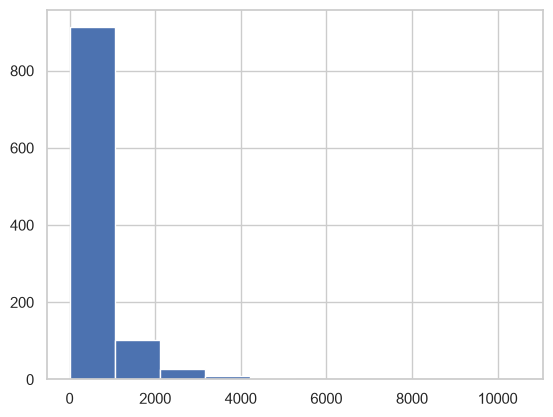

In [99]:
plt.hist(ventes["MontantNet"])

In [100]:
plt.show()

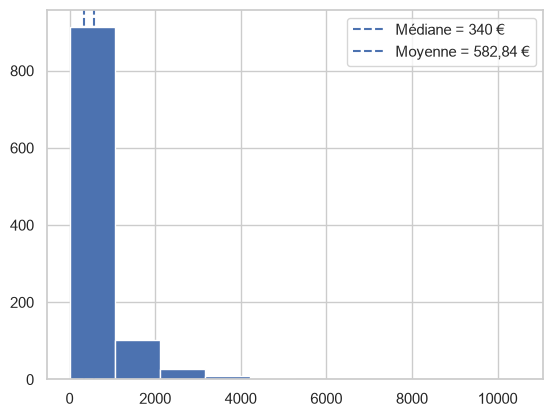

In [101]:
plt.hist(ventes["MontantNet"])

plt.axvline(340, linestyle="--", label="Médiane = 340 €")
plt.axvline(582.84, linestyle="--", label="Moyenne = 582,84 €")

plt.legend()
plt.show()

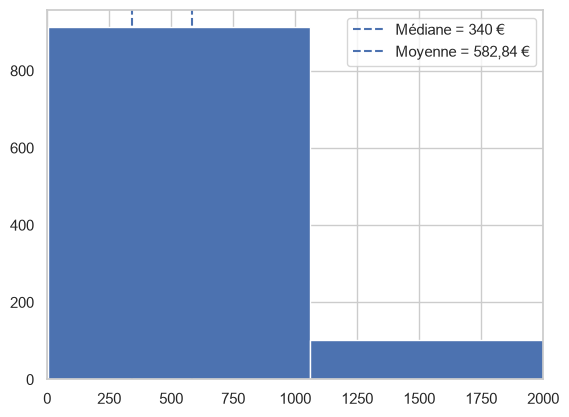

In [102]:
plt.hist(ventes["MontantNet"])

plt.axvline(340, linestyle="--", label="Médiane = 340 €")
plt.axvline(582.84, linestyle="--", label="Moyenne = 582,84 €")

plt.xlim(0, 2000)

plt.legend()
plt.show()

In [103]:
outliers = ventes[ventes["MontantNet"] > 1509.70]

In [104]:
outliers

,OrderID,CustomerID,EmployeeID,OrderDate,ShippedDate,ProductID,Quantity,UnitPrice,Discount,FirstName,...,Country,City,MontantBrut,MontantNet,Mois,CategoryID,CategoryName,StandardCost,CoutLigne,MargeBrute
6,10789,FOLIG,1,2017-12-22,2017-12-31,18,30,62.5,0.00,Nancy,...,France,Lille,1875.0,1875.000,2017-12,8,Seafood,40.50,1215.00,660.000
16,10776,ERNSH,1,2017-12-15,2017-12-18,51,120,53.0,0.05,Nancy,...,Austria,Graz,6360.0,6042.000,2017-12,7,Produce,31.38,3765.60,2276.400
41,10709,GOURL,1,2017-10-17,2017-11-20,8,40,40.0,0.00,Nancy,...,Brazil,Campinas,1600.0,1600.000,2017-10,2,Condiments,20.16,806.40,793.600
72,10618,MEREP,1,2017-08-01,2017-08-08,6,70,25.0,0.00,Nancy,...,Canada,Montral,1750.0,1750.000,2017-08,2,Condiments,13.60,952.00,798.000
75,10616,GREAL,1,2017-07-31,2017-08-05,38,15,263.5,0.05,Nancy,...,USA,Eugene,3952.5,3754.875,2017-07,1,Beverages,152.83,2292.45,1462.425
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
922,10660,HUNGC,8,2017-09-08,2017-10-15,20,21,81.0,0.00,Laura,...,USA,Elgin,1701.0,1701.000,2017-09,3,Confections,46.49,976.29,724.710
1012,10402,ERNSH,8,2017-01-02,2017-01-10,63,65,35.1,0.00,Laura,...,Austria,Graz,2281.5,2281.500,2017-01,2,Condiments,21.77,1415.05,866.450
1023,10745,QUICK,9,2017-11-18,2017-11-27,59,45,55.0,0.00,Anne,...,Germany,Cunewalde,2475.0,2475.000,2017-11,4,Dairy Products,34.10,1534.50,940.500
1029,10687,HUNGO,9,2017-09-30,2017-10-30,2,50,97.0,0.25,Anne,...,Ireland,Cork,4850.0,3637.500,2017-09,1,Beverages,10.87,543.50,3094.000


In [105]:
len(outliers)

79

In [106]:
outliers[
    ["OrderID", "ProductName", "Quantity", "UnitPrice", "Discount", "MontantNet"]
].head(10)

,OrderID,ProductName,Quantity,UnitPrice,Discount,MontantNet
6,10789,Carnarvon Tigers,30,62.5,0.00,1875.000
16,10776,Manjimup Dried Apples,120,53.0,0.05,6042.000
41,10709,Northwoods Cranberry Sauce,40,40.0,0.00,1600.000
72,10618,Grandma's Boysenberry Spread,70,25.0,0.00,1750.000
75,10616,Cte de Blaye,15,263.5,0.05,3754.875
79,10612,Ikura,70,31.0,0.00,2170.000
86,10605,Camembert Pierrot,70,34.0,0.05,2261.000
90,10598,Schoggi Schokolade,50,43.9,0.00,2195.000
102,10567,Raclette Courdavault,40,55.0,0.20,1760.000
112,10546,Tarte au sucre,40,49.3,0.00,1972.000


In [107]:
correlation = ventes["Quantity"].corr(ventes["Discount"]
)

In [108]:
correlation


np.float64(0.07360246396815284)

In [109]:
avec_remise = ventes[ventes["Discount"] > 0]

sans_remise = ventes[ventes["Discount"] == 0]

In [110]:
avec_remise 

,OrderID,CustomerID,EmployeeID,OrderDate,ShippedDate,ProductID,Quantity,UnitPrice,Discount,FirstName,...,Country,City,MontantBrut,MontantNet,Mois,CategoryID,CategoryName,StandardCost,CoutLigne,MargeBrute
0,10800,SEVES,1,2017-12-26,2018-01-05,11,50,21.00,0.10,Nancy,...,UK,London,1050.00,945.000,2017-12,4,Dairy Products,13.19,659.50,285.500
1,10800,SEVES,1,2017-12-26,2018-01-05,51,10,53.00,0.10,Nancy,...,UK,London,530.00,477.000,2017-12,7,Produce,31.38,313.80,163.200
2,10800,SEVES,1,2017-12-26,2018-01-05,54,7,7.45,0.10,Nancy,...,UK,London,52.15,46.935,2017-12,6,Meat/Poultry,5.19,36.33,10.605
10,10788,QUICK,1,2017-12-22,2018-01-19,75,40,7.75,0.05,Nancy,...,Germany,Cunewalde,310.00,294.500,2017-12,1,Beverages,4.62,184.80,109.700
13,10776,ERNSH,1,2017-12-15,2017-12-18,31,16,12.50,0.05,Nancy,...,Austria,Graz,200.00,190.000,2017-12,4,Dairy Products,7.75,124.00,66.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1053,10475,SUPRD,9,2017-03-14,2017-04-04,66,60,13.60,0.15,Anne,...,Belgium,Charleroi,816.00,693.600,2017-03,2,Condiments,8.84,530.40,163.200
1054,10475,SUPRD,9,2017-03-14,2017-04-04,76,42,14.40,0.15,Anne,...,Belgium,Charleroi,604.80,514.080,2017-03,1,Beverages,10.87,456.54,57.540
1055,10411,BOTTM,9,2017-01-10,2017-01-21,41,25,7.70,0.20,Anne,...,Canada,Tsawassen,192.50,154.000,2017-01,8,Seafood,6.41,160.25,-6.250
1056,10411,BOTTM,9,2017-01-10,2017-01-21,44,40,15.50,0.20,Anne,...,Canada,Tsawassen,620.00,496.000,2017-01,2,Condiments,9.96,398.40,97.600


In [111]:
sans_remise

,OrderID,CustomerID,EmployeeID,OrderDate,ShippedDate,ProductID,Quantity,UnitPrice,Discount,FirstName,...,Country,City,MontantBrut,MontantNet,Mois,CategoryID,CategoryName,StandardCost,CoutLigne,MargeBrute
3,10792,WOLZA,1,2017-12-23,2017-12-31,2,10,19.00,0.0,Nancy,...,Poland,Warszawa,190.00,190.00,2017-12,1,Beverages,10.87,108.70,81.30
4,10792,WOLZA,1,2017-12-23,2017-12-31,54,3,7.45,0.0,Nancy,...,Poland,Warszawa,22.35,22.35,2017-12,6,Meat/Poultry,5.19,15.57,6.78
5,10792,WOLZA,1,2017-12-23,2017-12-31,68,15,12.50,0.0,Nancy,...,Poland,Warszawa,187.50,187.50,2017-12,3,Confections,7.08,106.20,81.30
6,10789,FOLIG,1,2017-12-22,2017-12-31,18,30,62.50,0.0,Nancy,...,France,Lille,1875.00,1875.00,2017-12,8,Seafood,40.50,1215.00,660.00
7,10789,FOLIG,1,2017-12-22,2017-12-31,35,15,18.00,0.0,Nancy,...,France,Lille,270.00,270.00,2017-12,1,Beverages,10.01,150.15,119.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1045,10557,LEHMS,9,2017-06-03,2017-06-06,64,30,33.25,0.0,Anne,...,Germany,Frankfurt a.M.,997.50,997.50,2017-06,5,Grains/Cereals,16.09,482.70,514.80
1046,10557,LEHMS,9,2017-06-03,2017-06-06,75,20,7.75,0.0,Anne,...,Germany,Frankfurt a.M.,155.00,155.00,2017-06,1,Beverages,4.62,92.40,62.60
1047,10538,BSBEV,9,2017-05-15,2017-05-16,70,7,15.00,0.0,Anne,...,UK,London,105.00,105.00,2017-05,1,Beverages,8.34,58.38,46.62
1048,10538,BSBEV,9,2017-05-15,2017-05-16,72,1,34.80,0.0,Anne,...,UK,London,34.80,34.80,2017-05,4,Dairy Products,21.30,21.30,13.50


In [112]:
quantite_moyenne_avec_remise = avec_remise["Quantity"].mean()

quantite_moyenne_sans_remise = sans_remise["Quantity"].mean()

In [113]:
quantite_moyenne_avec_remise, quantite_moyenne_sans_remise

(np.float64(26.01605504587156), np.float64(22.662379421221864))

In [114]:
correlation = ventes["MontantNet"].corr(ventes["Discount"]
)

In [115]:
correlation

np.float64(-0.037702625046443575)

### Interprétation des statistiques utiles

**Moyenne / médiane :**  
La moyenne du MontantNet est de **582,84 €**, contre une médiane de **340 €**. Certaines ventes ont probablement des montants beaucoup plus élevés que les ventes habituelles, ce qui tire la moyenne vers le haut.

**Outliers :**  
Les **79 lignes supérieures à 1 509,70 €** sont considérées comme des outliers potentiels selon la méthode de l'IQR. Elles correspondent à des ventes élevées, mais ne constituent pas nécessairement des erreurs : certaines peuvent être expliquées par des quantités importantes et/ou des prix unitaires élevés.

**Remise / quantité :**  
La corrélation de **0,0736** indique une relation linéaire positive très faible entre la remise et la quantité achetée.

**Remise / MontantNet :**  
La corrélation de **-0,0377** indique une relation linéaire négative très faible, pratiquement inexistante, entre la remise et le montant net.

**Corrélation et causalité :**  
Une corrélation indique seulement si deux variables ont tendance à évoluer ensemble. Elle ne permet pas d'affirmer que l'une provoque l'évolution de l'autre, car d'autres facteurs peuvent in

Les montants nets élevés ne semblent pas provenir d'une cause unique. Certains sont expliqués par des quantités importantes, tandis que d'autres proviennent de prix unitaires élevés. Dans certains cas, les deux effets se combinent.

## 8. Construire 4 à 6 visualisations décisionnelles


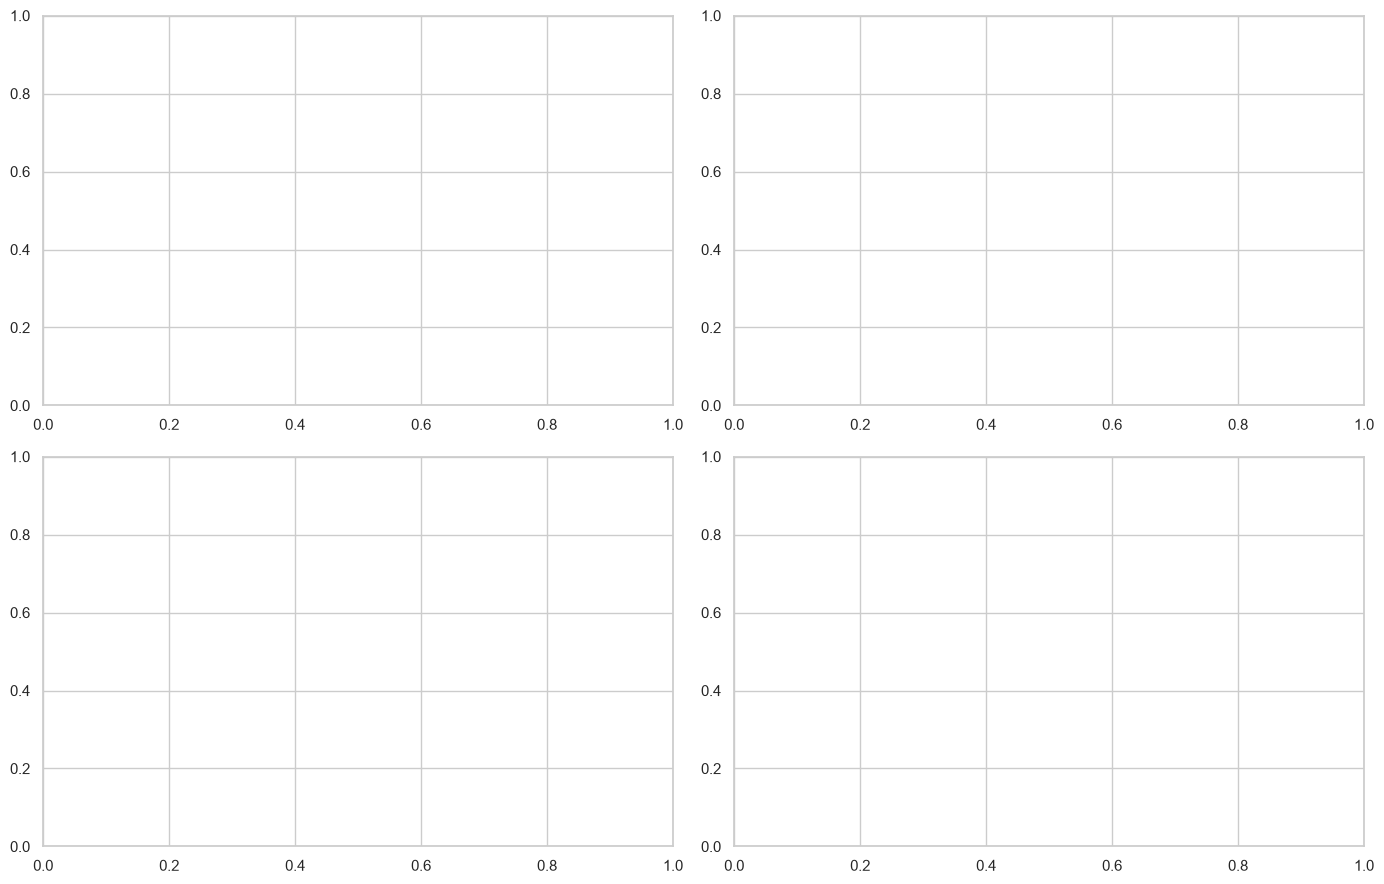

In [116]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# À COMPLÉTER :
# 1. tendance mensuelle ;
# 2. comparaison par région/pays ;
# 3. performance catégorie ou produit ;
# 4. distribution ou relation statistique.

plt.tight_layout()
plt.show()


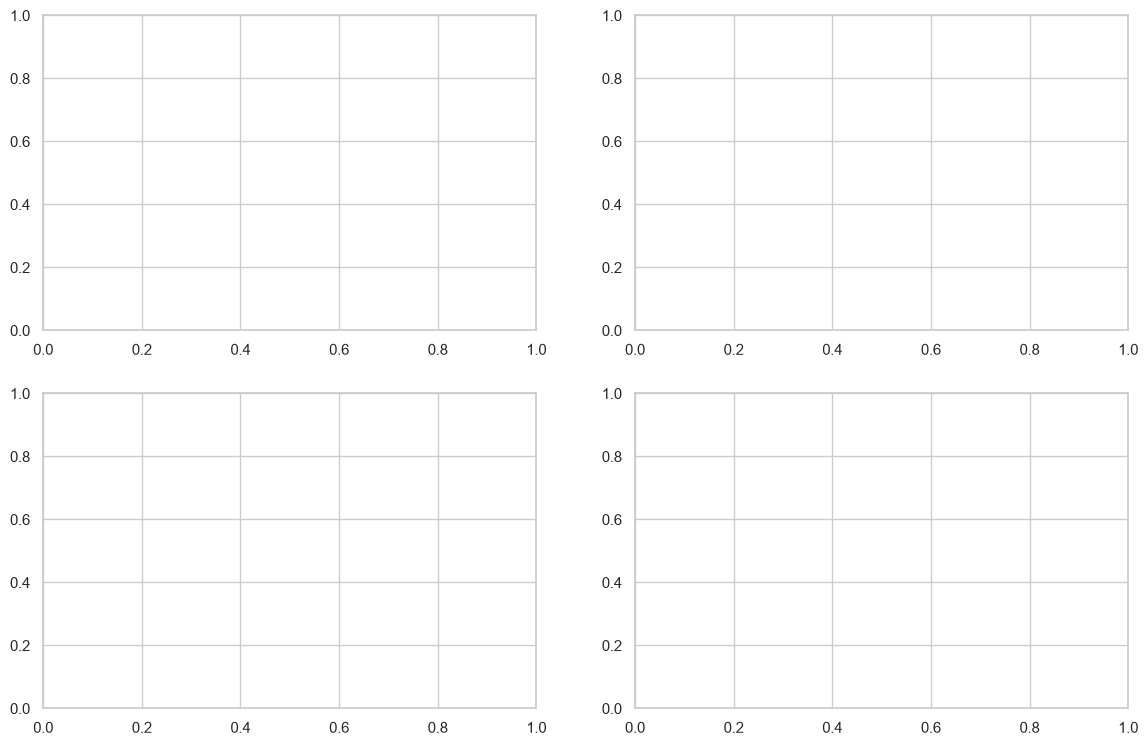

In [117]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

In [118]:
axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])

In [119]:
plt.show()

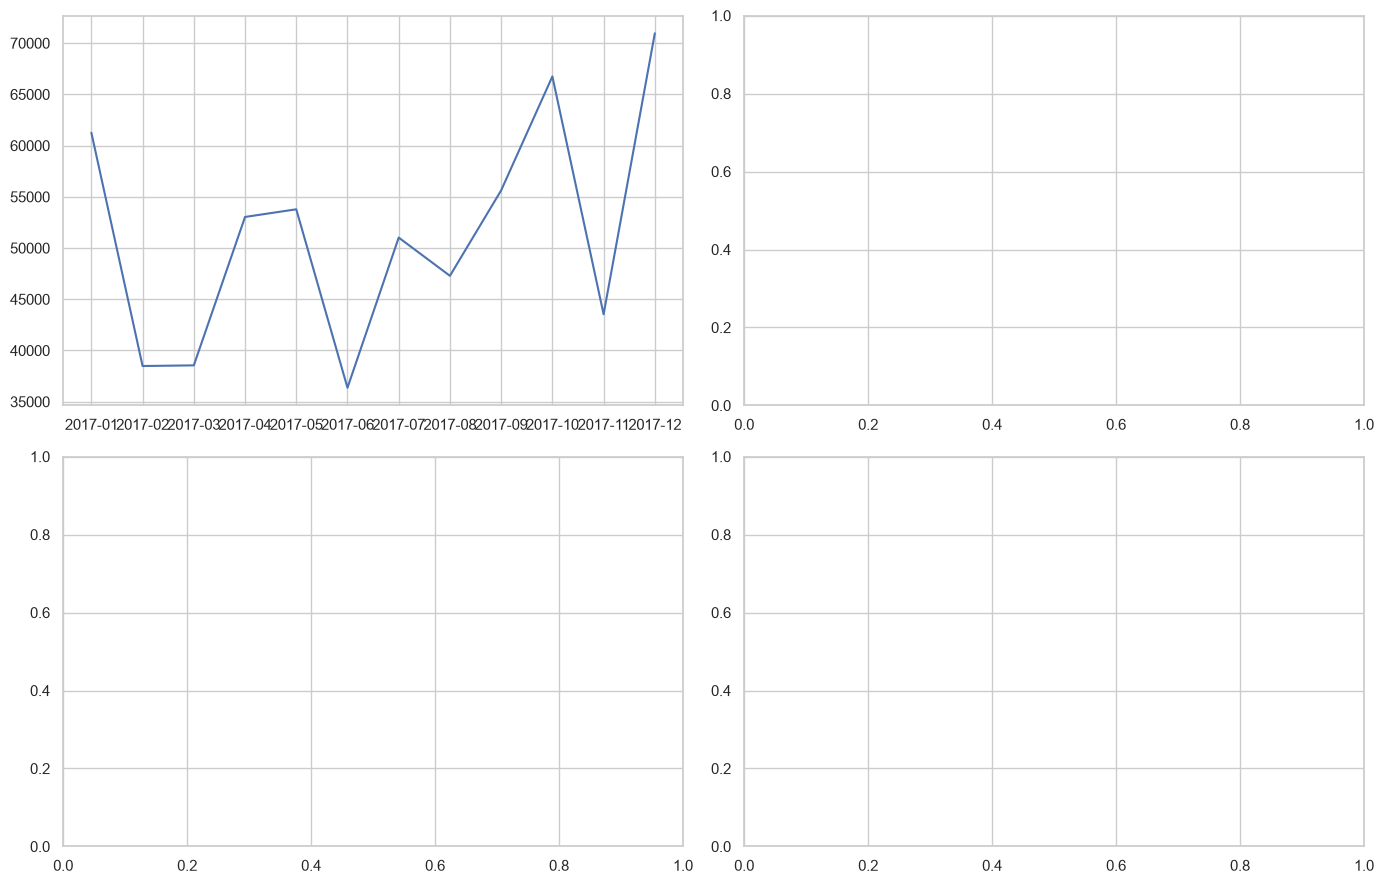

In [120]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])

plt.tight_layout()
plt.show()

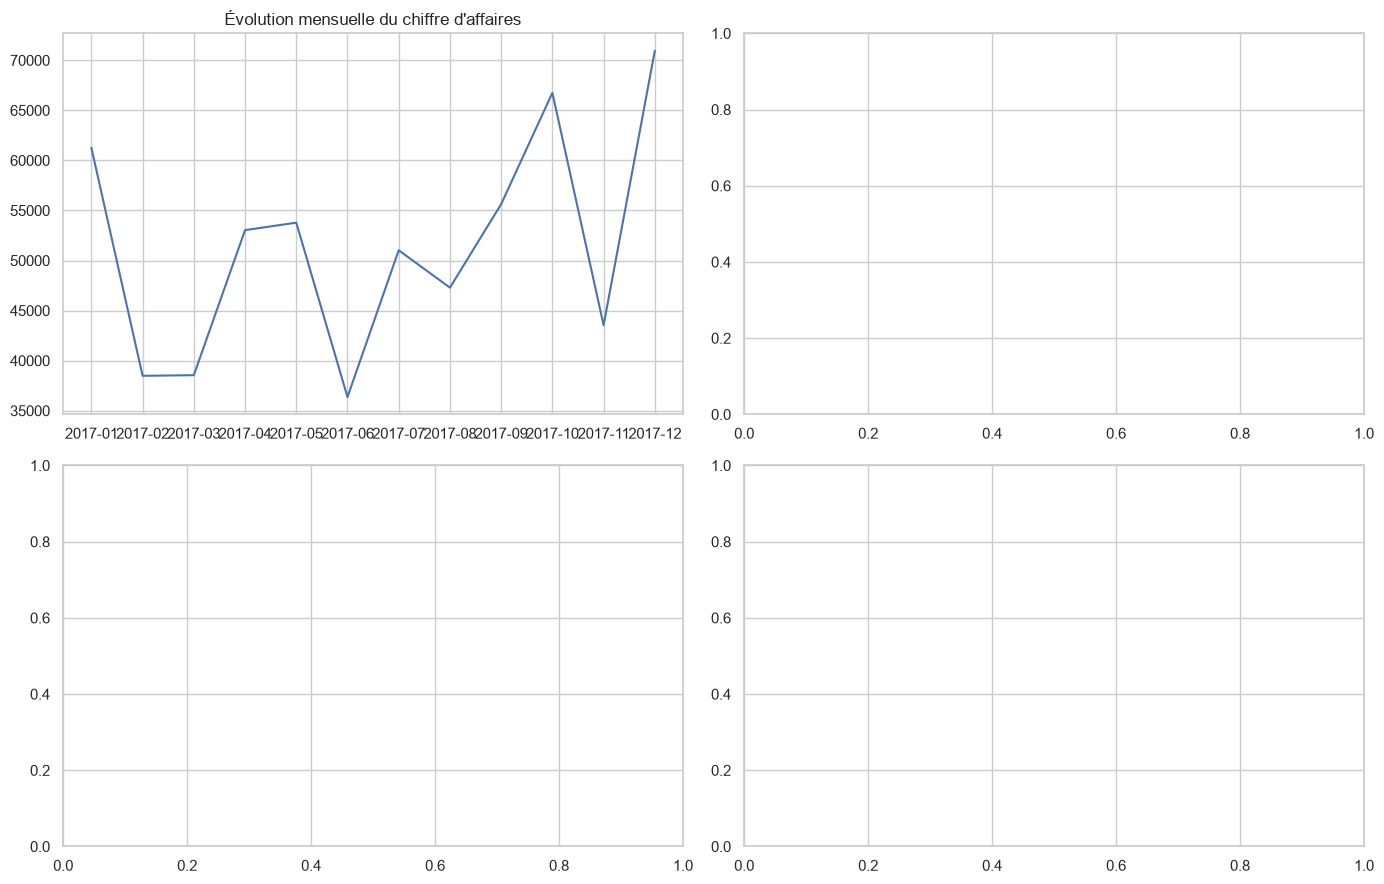

In [121]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])
axes[0, 0].set_title("Évolution mensuelle du chiffre d'affaires")

plt.tight_layout()
plt.show()

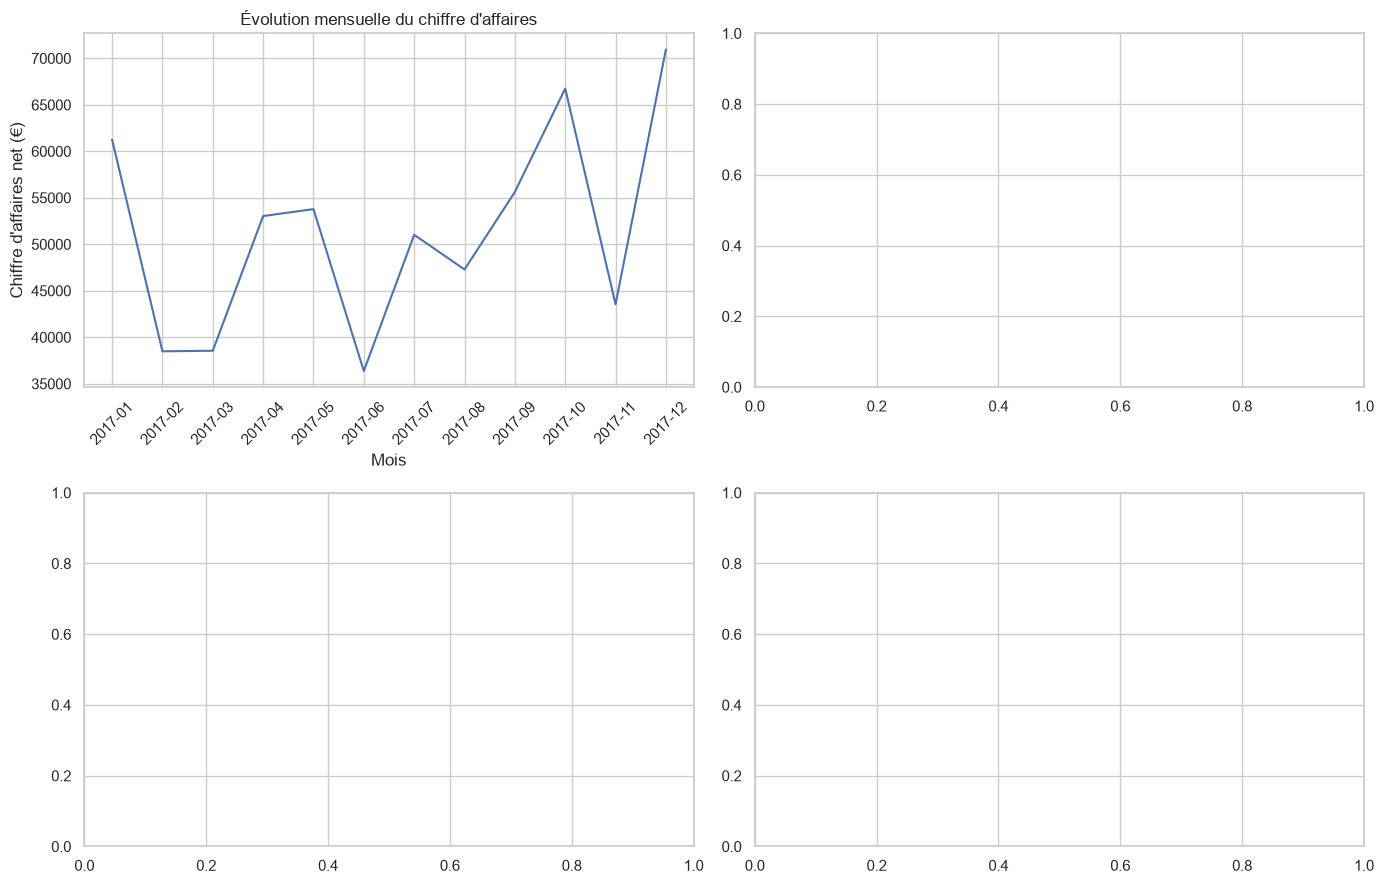

In [122]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])

axes[0, 0].set_title("Évolution mensuelle du chiffre d'affaires")
axes[0, 0].set_xlabel("Mois")
axes[0, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[0, 0].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [123]:
analyse_pays = ventes.groupby("Country").agg(
    CA_net=("MontantNet", "sum"),
    )

In [124]:
analyse_pays

,CA_net
Country,
Argentina,1816.6000
Austria,57401.8435
Belgium,11434.4800
Brazil,41941.1875
Canada,31298.0600
Denmark,25192.5375
Finland,13437.2925
France,45263.3825
Germany,116883.1645


In [125]:
analyse_pays = analyse_pays.sort_values(by="CA_net", ascending=False) 

In [126]:
analyse_pays

,CA_net
Country,
Germany,116883.1645
USA,114845.2625
Austria,57401.8435
France,45263.3825
Brazil,41941.1875
Canada,31298.0600
Sweden,27163.6850
UK,27074.0950
Venezuela,26404.9190


In [127]:
analyse_pays.head(5)

,CA_net
Country,
Germany,116883.1645
USA,114845.2625
Austria,57401.8435
France,45263.3825
Brazil,41941.1875


In [128]:
top5_pays = analyse_pays.head(5)

In [129]:
top5_pays

,CA_net
Country,
Germany,116883.1645
USA,114845.2625
Austria,57401.8435
France,45263.3825
Brazil,41941.1875


In [130]:
top5_pays = analyse_pays.head(5)

In [131]:
axes[0, 1].set_title("Top 5 des pays par chiffre d'affaires net")
axes[0, 1].bar(top5_pays.index, top5_pays["CA_net"])
axes[0, 1].set_xlabel("Pays")
axes[0, 1].set_ylabel("Chiffre d'affaires net (€)")


Text(716.0428602430555, 0.5, "Chiffre d'affaires net (€)")

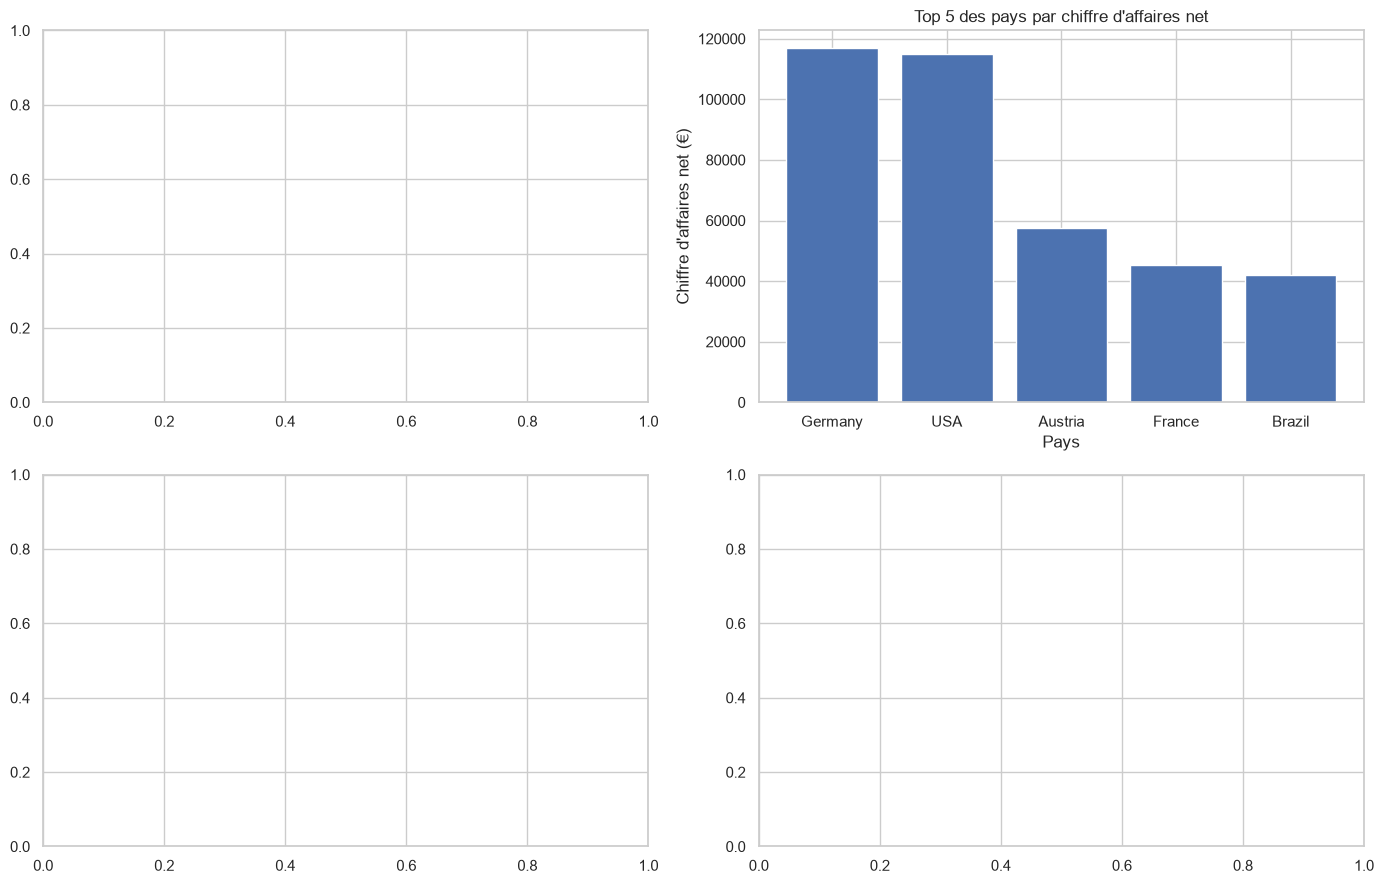

In [132]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))



# GRAPHIQUE 2
axes[0, 1].bar(top5_pays.index, top5_pays["CA_net"])
axes[0, 1].set_title("Top 5 des pays par chiffre d'affaires net")
axes[0, 1].set_xlabel("Pays")
axes[0, 1].set_ylabel("Chiffre d'affaires net (€)")

plt.tight_layout()
plt.show()
# GRAPHIQUE 1
axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])
axes[0, 0].set_title("Évolution mensuelle du chiffre d'affaires")
axes[0, 0].set_xlabel("Mois")
axes[0, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[0, 0].tick_params(axis="x", rotation=45)

In [133]:
analyse_categories = ventes.groupby("CategoryName").agg(
    CA_net=("MontantNet", "sum"),
    )

In [134]:
analyse_categories

,CA_net
CategoryName,
Beverages,110859.8050
Condiments,55368.5900
Confections,82220.7505
Dairy Products,115387.6400
Grains/Cereals,56871.8250
Meat/Poultry,74039.6080
Produce,54940.7675
Seafood,66959.2175


In [135]:
analyse_categories = analyse_categories.sort_values(by="CA_net", ascending=False)

In [136]:
analyse_categories

,CA_net
CategoryName,
Dairy Products,115387.6400
Beverages,110859.8050
Confections,82220.7505
Meat/Poultry,74039.6080
Seafood,66959.2175
Grains/Cereals,56871.8250
Condiments,55368.5900
Produce,54940.7675


In [137]:
# GRAPHIQUE 3
axes[1, 0].plot(analyse_categories.index, analyse_categories["CA_net"])
axes[1, 0].set_title("Évolution mensuelle du chiffre d'affaires")
axes[1, 0].set_xlabel("CategoryName")
axes[1, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[1, 0].tick_params(axis="x", rotation=45)

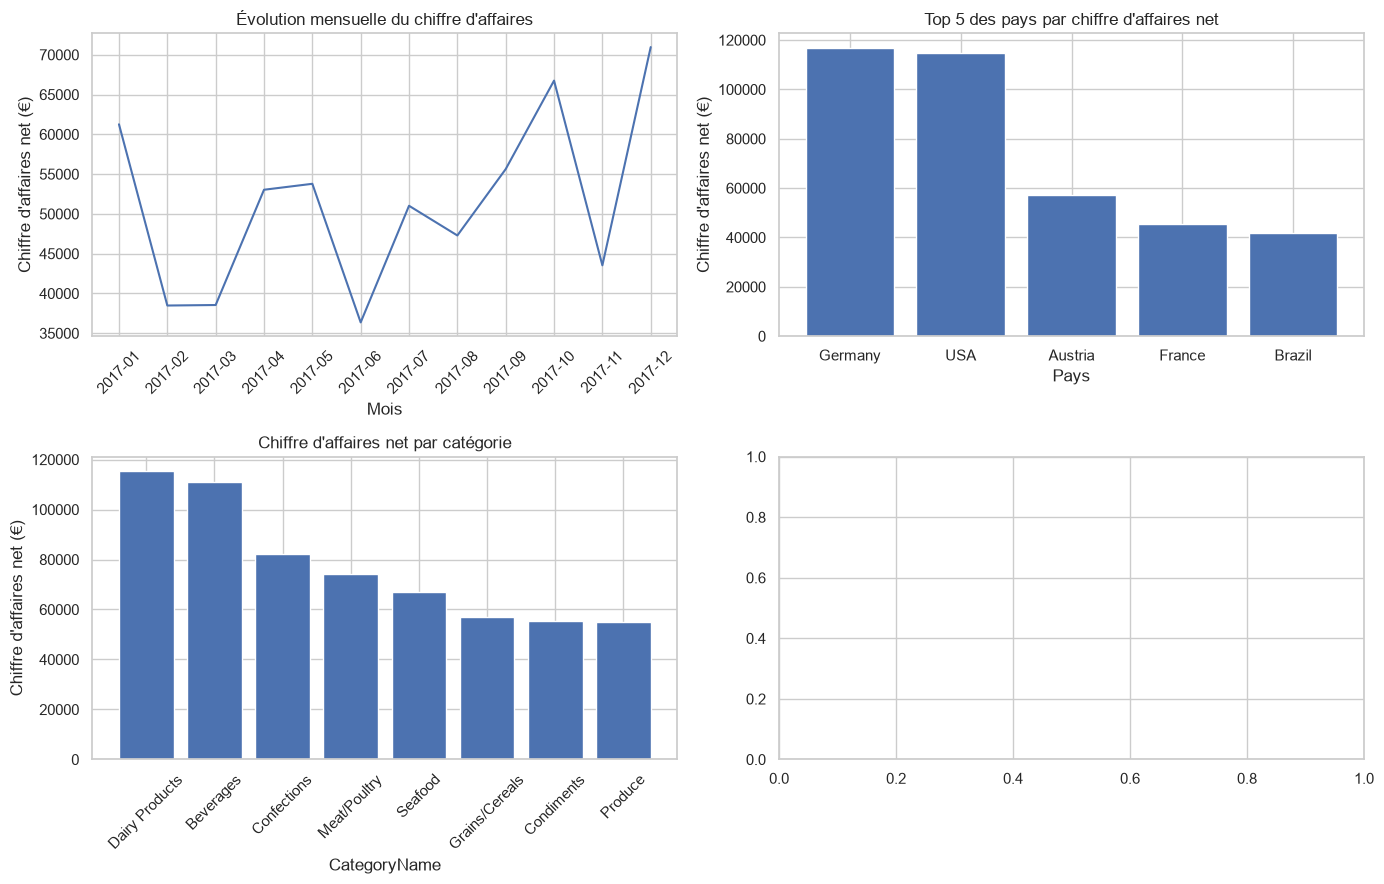

In [138]:


fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# GRAPHIQUE 1
axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])
axes[0, 0].set_title("Évolution mensuelle du chiffre d'affaires")
axes[0, 0].set_xlabel("Mois")
axes[0, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[0, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 2
axes[0, 1].bar(top5_pays.index, top5_pays["CA_net"])
axes[0, 1].set_title("Top 5 des pays par chiffre d'affaires net")
axes[0, 1].set_xlabel("Pays")
axes[0, 1].set_ylabel("Chiffre d'affaires net (€)")

# GRAPHIQUE 3
axes[1, 0].bar(analyse_categories.index, analyse_categories["CA_net"])
axes[1, 0].set_title("Chiffre d'affaires net par catégorie")
axes[1, 0].set_xlabel("CategoryName")
axes[1, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[1, 0].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [139]:
axes[1, 1].scatter(ventes["Discount"], ventes["Quantity"])

In [140]:
analyse_Correlation = ventes.groupby("Discount").agg(
    CA_net=("MontantNet", "sum"),
    )

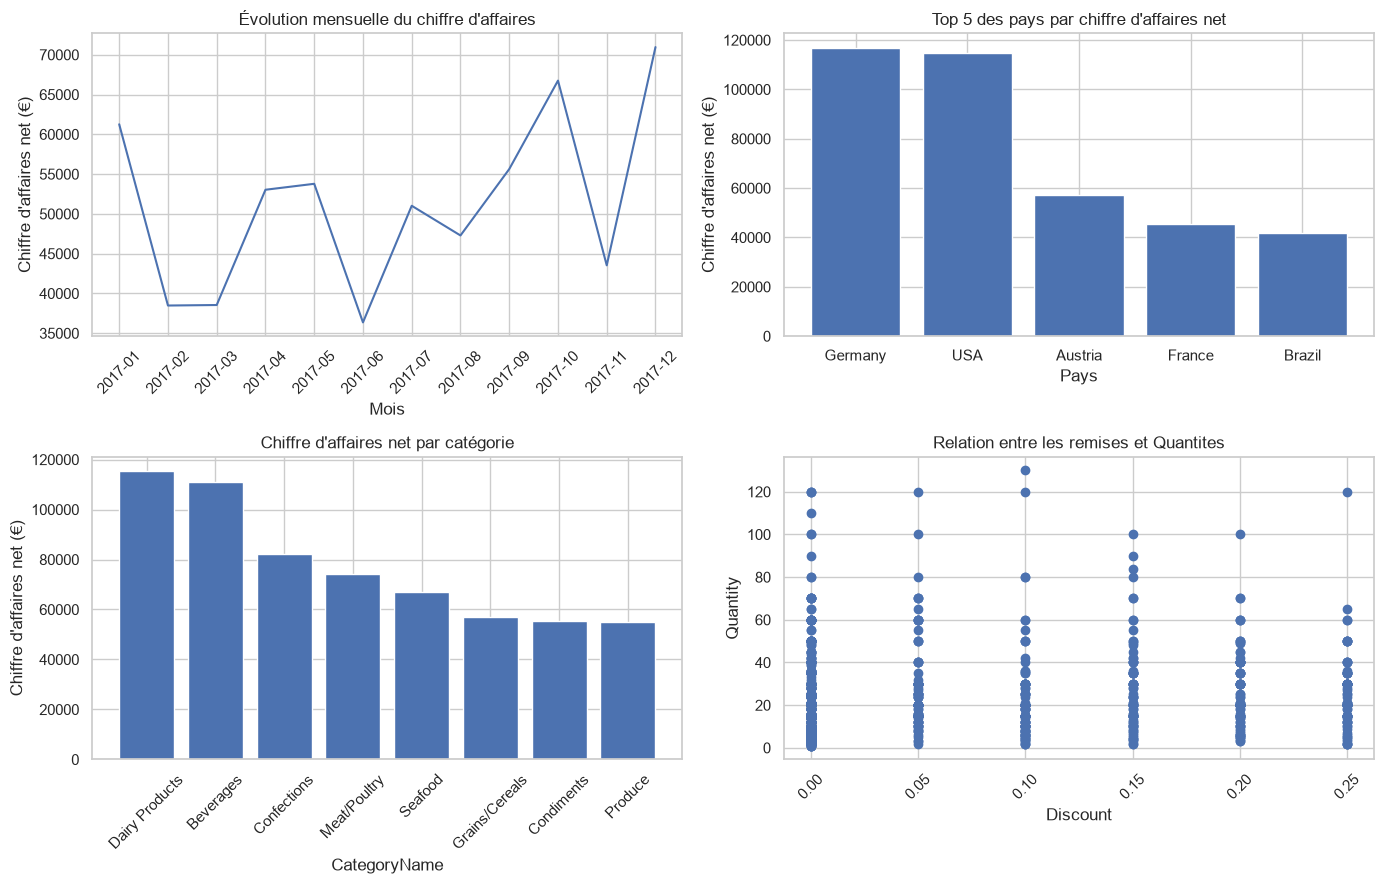

In [141]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# GRAPHIQUE 1
axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])
axes[0, 0].set_title("Évolution mensuelle du chiffre d'affaires")
axes[0, 0].set_xlabel("Mois")
axes[0, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[0, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 2
axes[0, 1].bar(top5_pays.index, top5_pays["CA_net"])
axes[0, 1].set_title("Top 5 des pays par chiffre d'affaires net")
axes[0, 1].set_xlabel("Pays")
axes[0, 1].set_ylabel("Chiffre d'affaires net (€)")

# GRAPHIQUE 3
axes[1, 0].bar(analyse_categories.index, analyse_categories["CA_net"])
axes[1, 0].set_title("Chiffre d'affaires net par catégorie")
axes[1, 0].set_xlabel("CategoryName")
axes[1, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[1, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 4
axes[1, 1].scatter(ventes["Discount"], ventes["Quantity"])
axes[1, 1].set_title("Relation entre les remises et Quantites")
axes[1, 1].set_xlabel("Discount")
axes[1, 1].set_ylabel("Quantity")
axes[1, 1].tick_params(axis="x", rotation=45)


plt.tight_layout()
plt.show()

In [142]:
groupe_0 = ventes[ventes["Discount"] == 0]["Quantity"]

In [143]:
groupe_0

3       10
4        3
5       15
6       30
7       15
        ..
1045    30
1046    20
1047     7
1048     1
1051    20
Name: Quantity, Length: 622, dtype: int64

In [144]:
groupe_5 = ventes[ventes["Discount"] == 0.05]["Quantity"]

In [145]:
groupe_5

10      40
13      16
14      12
15      27
16     120
      ... 
961     50
963     24
976      2
978     80
991    100
Name: Quantity, Length: 97, dtype: int64

In [146]:
groupe_10 = ventes[ventes["Discount"] == 0.10]["Quantity"]

In [147]:
groupe_10

0       50
1       10
2        7
55       8
56       4
        ..
952     18
1007    20
1032    15
1049    18
1050    14
Name: Quantity, Length: 98, dtype: int64

In [148]:
groupe_15 = ventes[ventes["Discount"] == 0.15]["Quantity"]

In [149]:
groupe_15

50      30
51       8
61      24
62      12
63      15
        ..
1042    35
1043    18
1052    35
1053    60
1054    42
Name: Quantity, Length: 78, dtype: int64

In [150]:
groupe_20 = ventes[ventes["Discount"] == 0.20]["Quantity"]

In [151]:
groupe_20

18      70
19       7
64      20
100     60
102     40
        ..
993      6
994      6
1055    25
1056    40
1057     9
Name: Quantity, Length: 87, dtype: int64

In [152]:
groupe_25 = ventes[ventes["Discount"] == 0.25]["Quantity"]

In [153]:
groupe_25

44      20
45      30
46      35
47      50
48      20
        ..
1031     6
1034    15
1035    18
1036    30
1037    35
Name: Quantity, Length: 76, dtype: int64

In [154]:
groupes = [groupe_0, groupe_5, groupe_10, groupe_15, groupe_20, groupe_25]

axes[1, 1].boxplot(groupes)

{'whiskers': [<matplotlib.lines.Line2D at 0x1872bd01400>,
 'caps': [<matplotlib.lines.Line2D at 0x1872bd016a0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1872bd012b0>,
 'medians': [<matplotlib.lines.Line2D at 0x1872bd01940>,
 'fliers': [<matplotlib.lines.Line2D at 0x1872bd01a90>,
 'means': []}

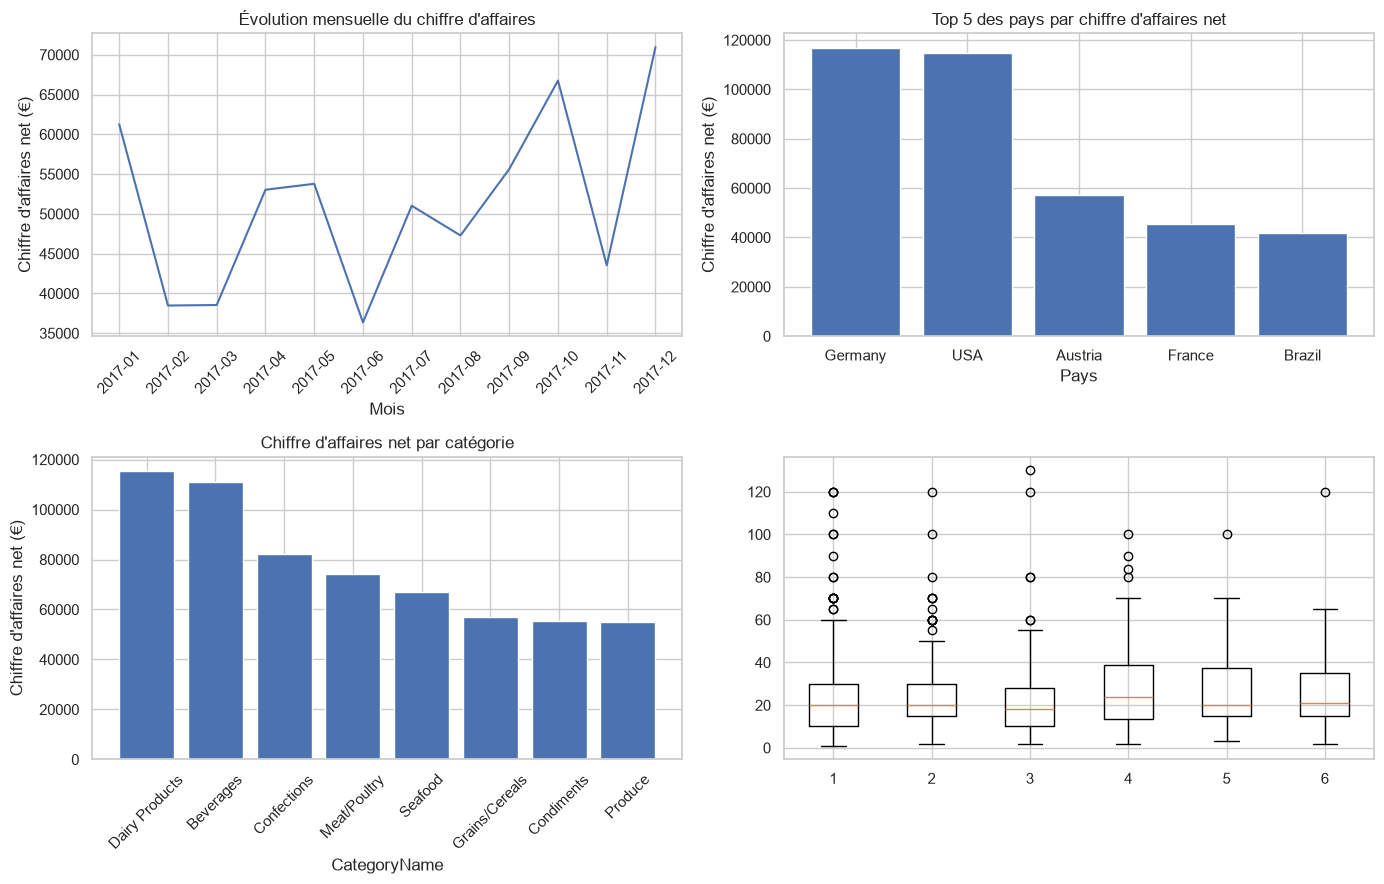

In [155]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# GRAPHIQUE 1
axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])
axes[0, 0].set_title("Évolution mensuelle du chiffre d'affaires")
axes[0, 0].set_xlabel("Mois")
axes[0, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[0, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 2
axes[0, 1].bar(top5_pays.index, top5_pays["CA_net"])
axes[0, 1].set_title("Top 5 des pays par chiffre d'affaires net")
axes[0, 1].set_xlabel("Pays")
axes[0, 1].set_ylabel("Chiffre d'affaires net (€)")

# GRAPHIQUE 3
axes[1, 0].bar(analyse_categories.index, analyse_categories["CA_net"])
axes[1, 0].set_title("Chiffre d'affaires net par catégorie")
axes[1, 0].set_xlabel("CategoryName")
axes[1, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[1, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 4
groupes = [groupe_0, groupe_5, groupe_10, groupe_15, groupe_20, groupe_25]

axes[1, 1].boxplot(groupes)
plt.tight_layout()
plt.show()

In [156]:
len(groupe_0), len(groupe_5), len(groupe_10), len(groupe_15), len(groupe_20), len(groupe_25)

(622, 97, 98, 78, 87, 76)

In [157]:
ventes["Discount"].value_counts().sort_index()

Discount
0.00    622
0.05     97
0.10     98
0.15     78
0.20     87
0.25     76
Name: count, dtype: int64

In [158]:
groupes = [groupe_0, groupe_5, groupe_10, groupe_15, groupe_20, groupe_25]

In [159]:
[len(g) for g in groupes]

[622, 97, 98, 78, 87, 76]

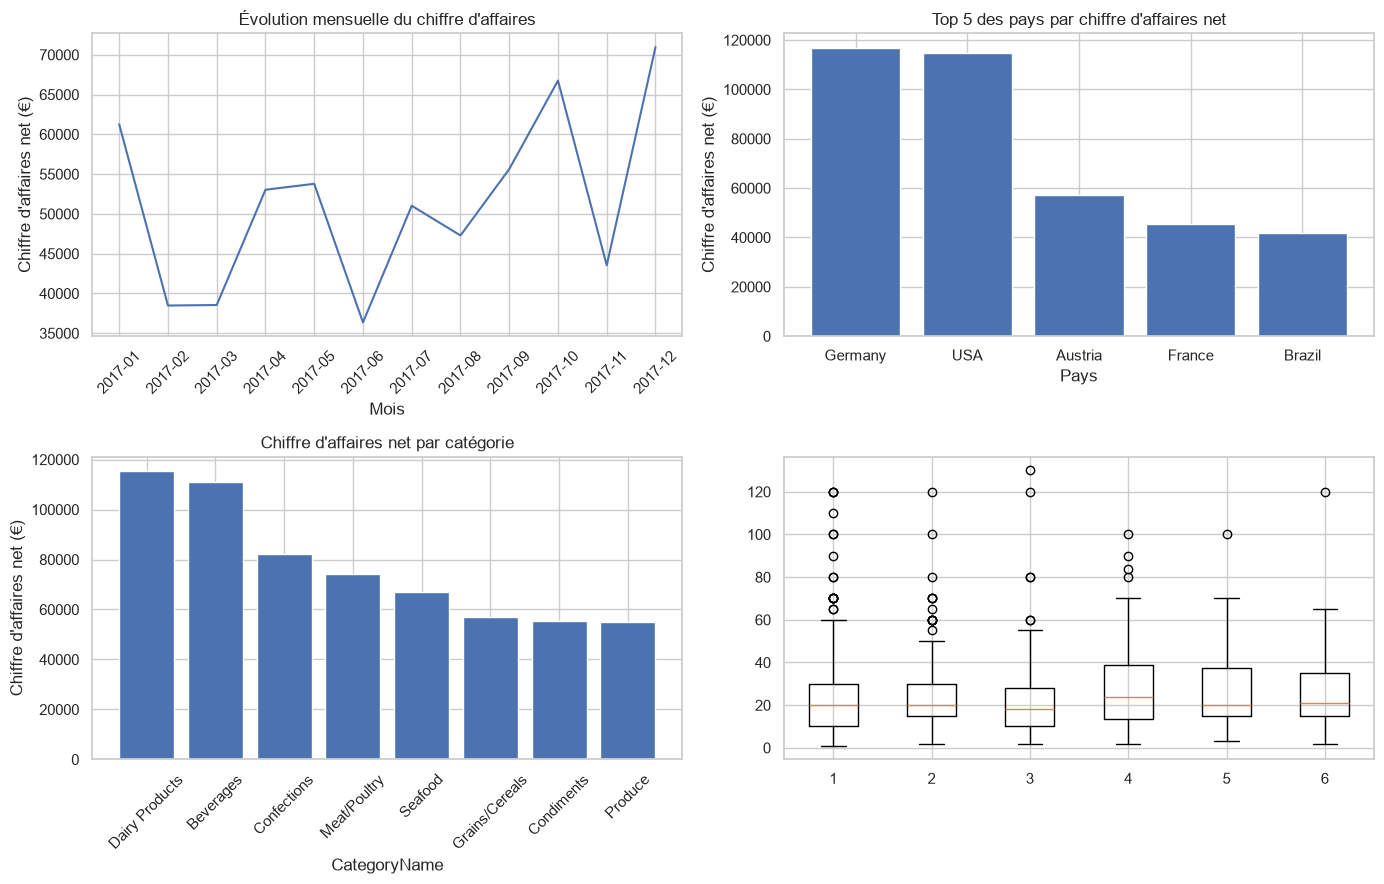

In [160]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# GRAPHIQUE 1
axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])
axes[0, 0].set_title("Évolution mensuelle du chiffre d'affaires")
axes[0, 0].set_xlabel("Mois")
axes[0, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[0, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 2
axes[0, 1].bar(top5_pays.index, top5_pays["CA_net"])
axes[0, 1].set_title("Top 5 des pays par chiffre d'affaires net")
axes[0, 1].set_xlabel("Pays")
axes[0, 1].set_ylabel("Chiffre d'affaires net (€)")

# GRAPHIQUE 3
axes[1, 0].bar(analyse_categories.index, analyse_categories["CA_net"])
axes[1, 0].set_title("Chiffre d'affaires net par catégorie")
axes[1, 0].set_xlabel("CategoryName")
axes[1, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[1, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 4
groupes = [groupe_0, groupe_5, groupe_10, groupe_15, groupe_20, groupe_25]

axes[1, 1].boxplot(groupes)
plt.tight_layout()
plt.show()

In [161]:
axes[1, 1].boxplot(
    groupes,
    tick_labels=["0%", "5%", "10%", "15%", "20%", "25%"]
)

axes[1, 1].set_title("Distribution des quantités selon la remise")
axes[1, 1].set_xlabel("Remise")
axes[1, 1].set_ylabel("Quantité")

Text(741.3363585379005, 0.5, 'Quantité')

In [162]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

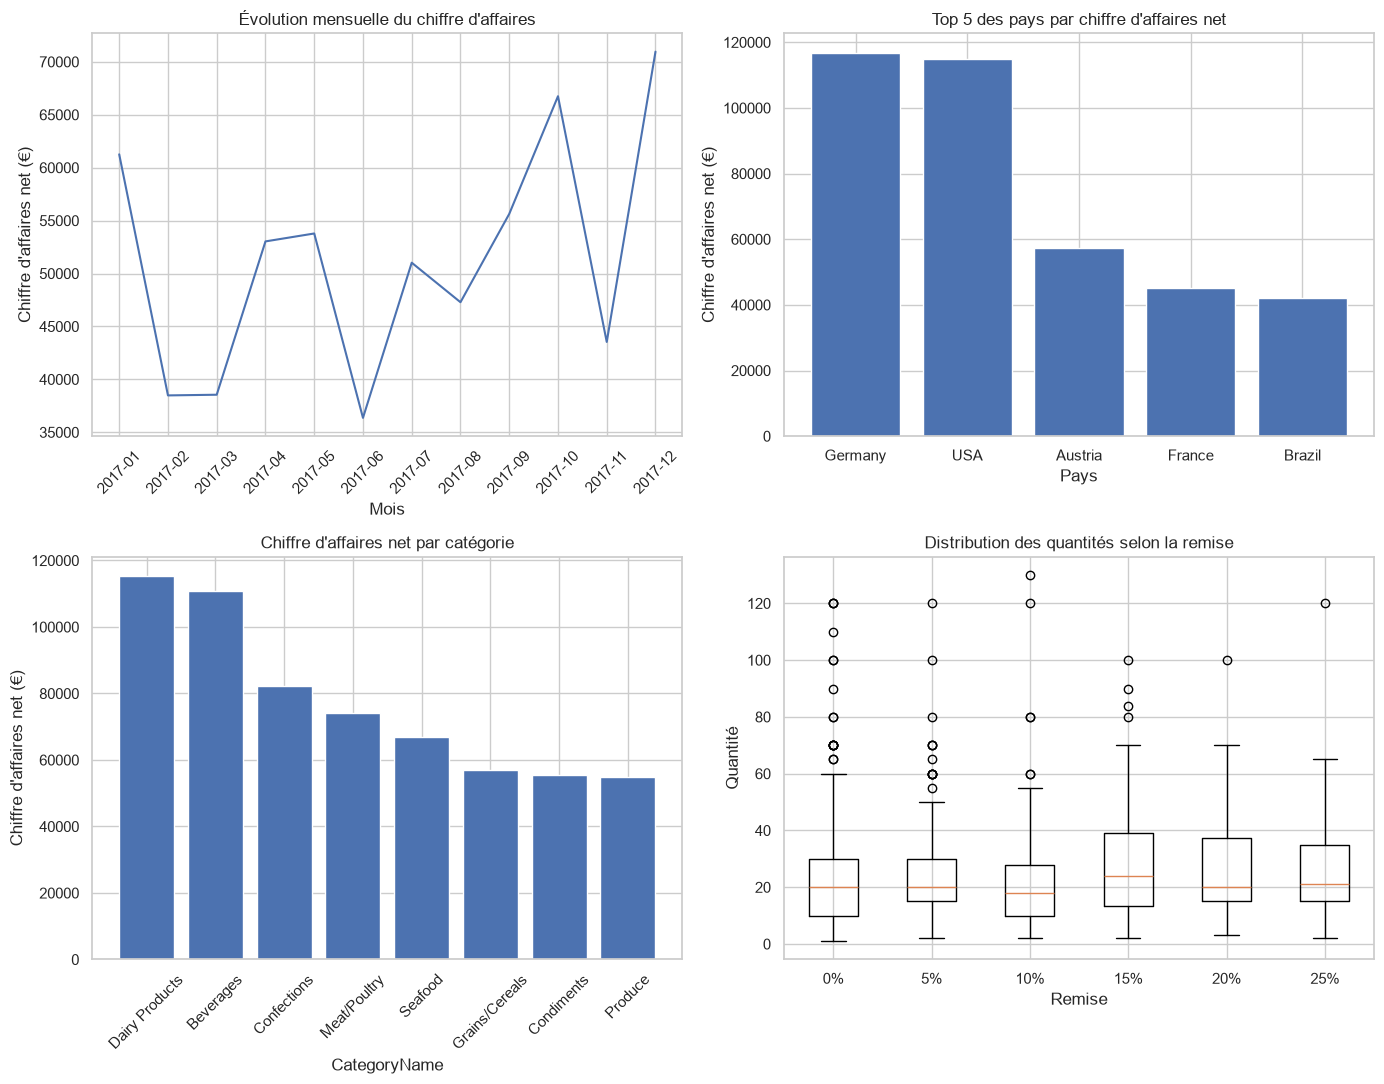

In [163]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# GRAPHIQUE 1
axes[0, 0].plot(analyse_mois.index, analyse_mois["CA_net"])
axes[0, 0].set_title("Évolution mensuelle du chiffre d'affaires")
axes[0, 0].set_xlabel("Mois")
axes[0, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[0, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 2
axes[0, 1].bar(top5_pays.index, top5_pays["CA_net"])
axes[0, 1].set_title("Top 5 des pays par chiffre d'affaires net")
axes[0, 1].set_xlabel("Pays")
axes[0, 1].set_ylabel("Chiffre d'affaires net (€)")

# GRAPHIQUE 3
axes[1, 0].bar(analyse_categories.index, analyse_categories["CA_net"])
axes[1, 0].set_title("Chiffre d'affaires net par catégorie")
axes[1, 0].set_xlabel("CategoryName")
axes[1, 0].set_ylabel("Chiffre d'affaires net (€)")
axes[1, 0].tick_params(axis="x", rotation=45)

# GRAPHIQUE 4
axes[1, 1].boxplot(
    groupes,
    tick_labels=["0%", "5%", "10%", "15%", "20%", "25%"]
)

axes[1, 1].set_title("Distribution des quantités selon la remise")
axes[1, 1].set_xlabel("Remise")
axes[1, 1].set_ylabel("Quantité")

plt.tight_layout()
plt.show()

### Objectifs des visualisations

1. **Tendance mensuelle**  
   La tendance mensuelle permet de suivre l'évolution de l'activité mois par mois au cours de l'année et d'identifier les périodes de hausse ou de baisse du chiffre d'affaires.

2. **Comparaison par pays**  
   La comparaison par pays permet d'observer les différences d'activité entre les différents marchés et d'identifier les pays qui contribuent le plus ou le moins au chiffre d'affaires.

3. **Performance par catégorie**  
   La comparaison par catégorie permet d'identifier les catégories de produits qui génèrent le plus ou le moins de chiffre d'affaires et ainsi d'apprécier celles qui performent le mieux.

4. **Relation entre remise et quantité**  
   L'analyse de la relation entre la remise (`Discount`) et la quantité (`Quantity`) permet de vérifier si le niveau de remise accordé semble avoir une incidence sur le volume des quantités achetées.

## 9. Contrôler la qualité des graphiques


Vérifiez :
- titre formulé comme un message utile ;
- axes et unités ;
- tri logique ;
- nombre de catégories lisible ;
- couleurs sobres et cohérentes ;
- absence de 3D et de décoration inutile ;
- périmètre indiqué lorsque nécessaire.


 Contrôle qualité des graphiques

1. **Titre formulé comme un message utile**  
   Un titre explicite permet au lecteur de comprendre immédiatement ce que représente le graphique, par exemple l'évolution du chiffre d'affaires mois par mois sur l'année 2017.

2. **Axes et unités**  
   Les axes et les unités sont clairement indiqués : l'axe horizontal représente les mois et l'axe vertical le chiffre d'affaires net en euros (€).

3. **Tri logique**  
   Le tri des données doit être adapté au graphique. Pour l'analyse temporelle, les mois sont présentés dans l'ordre chronologique de janvier à décembre afin de suivre correctement l'évolution de l'activité.

4. **Nombre de catégories lisible**  
   Le nombre de catégories affichées doit rester lisible afin de permettre au lecteur d'identifier et de comparer facilement les produits ou catégories, sans risque de confusion.

5. **Couleurs sobres et cohérentes**  
   Des couleurs sobres et cohérentes réduisent la surcharge visuelle et facilitent une lecture simple et rapide des informations présentées.

6. **Absence de 3D et de décoration inutile**  
   Les graphiques 2D simples sont privilégiés afin d'éviter toute surcharge visuelle. Les effets 3D n'apportent pas d'information supplémentaire et peuvent compliquer la lecture ou entraîner une mauvaise interprétation.

7. **Périmètre indiqué lorsque nécessaire**  
   Le périmètre est précisé afin de bien délimiter les données prises en compte dans l'analyse et d'éviter d'interpréter les résultats au-delà de la période étudiée. Ici, l'analyse porte sur les ventes de l'année 2017.

## 10. Synthèse pour la direction


### Trois constats chiffrés
1. À compléter
2. À compléter
3. À compléter

### Trois recommandations
1. À compléter — résultat qui la justifie :
2. À compléter — résultat qui la justifie :
3. À compléter — résultat qui la justifie :

### Deux limites
- À compléter
- À compléter

### Une analyse complémentaire à demander
- À compléter


### Synthèse pour la direction

#### 1. Trois constats chiffrés

- En décembre 2017, le chiffre d’affaires net atteint **70 961,43 €** pour **48 commandes**, avec un panier moyen de **1 478,36 € par commande**.
- **Germany** est le pays qui génère le chiffre d’affaires net le plus élevé, avec environ **116 883 €** sur la période analysée.
- **Dairy Products** est la catégorie qui génère le chiffre d’affaires net le plus élevé, avec environ **115 385 €** sur la période analysée.

#### 2. Trois recommandations

- **Anticiper les besoins en stock avant la période de forte activité de fin d’année** afin de limiter le risque de rupture.  
  **Résultat justificatif :** décembre 2017 présente le CA net mensuel le plus élevé avec **70 961,43 €** pour **48 commandes**.

- **Consolider le marché allemand et analyser les facteurs expliquant sa forte performance** afin d’identifier des leviers permettant de développer davantage les ventes.  
  **Résultat justificatif :** Germany génère environ **116 883 € de CA net**, le niveau le plus élevé parmi les pays analysés.

- **Analyser les facteurs expliquant la performance de Dairy Products** afin d’identifier les leviers qui pourraient être appliqués aux catégories moins performantes.  
  **Résultat justificatif :** Dairy Products génère environ **115 385 € de CA net**, le niveau le plus élevé parmi les catégories analysées.

#### 3. Deux limites de l’analyse

### Synthèse pour la direction

#### 1. Trois constats chiffrés

- En décembre 2017, le chiffre d’affaires net atteint **70 961,43 €** pour **48 commandes**, avec un panier moyen de **1 478,36 € par commande**.
- **Germany** est le pays qui génère le chiffre d’affaires net le plus élevé, avec environ **116 883 €** sur la période analysée.
- **Dairy Products** est la catégorie qui génère le chiffre d’affaires net le plus élevé, avec environ **115 385 €** sur la période analysée.

#### 2. Trois recommandations

- **Anticiper les besoins en stock avant la période de forte activité de fin d’année** afin de limiter le risque de rupture.  
  **Résultat justificatif :** décembre 2017 présente le CA net mensuel le plus élevé avec **70 961,43 €** pour **48 commandes**.

- **Consolider le marché allemand et analyser les facteurs expliquant sa forte performance** afin d’identifier des leviers permettant de développer davantage les ventes.  
  **Résultat justificatif :** Germany génère environ **116 883 € de CA net**, le niveau le plus élevé parmi les pays analysés.

- **Analyser les facteurs expliquant la performance de Dairy Products** afin d’identifier les leviers qui pourraient être appliqués aux catégories moins performantes.  
  **Résultat justificatif :** Dairy Products génère environ **115 387 € de CA net**, le niveau le plus élevé parmi les catégories analysées.

#### 3. Deux limites de l’analyse

## 11. Export final


In [164]:
# À COMPLÉTER selon votre table finale.
ventes.to_csv("outputs/foody_analyse_finale.csv", index=False)

print("Vérifiez une dernière fois Restart & Run All avant remise.")



Vérifiez une dernière fois Restart & Run All avant remise.
